In [1]:
import os
from pathlib import Path
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import torch

# Core crack_seg imports
from crack_seg import config
from crack_seg.data_handlers.dataset import CrackDataset
from crack_seg.data_handlers.dataset_loaders import (
    load_multiple_datasets,
    get_train_val_test_datasets,
    create_splits,
)
from crack_seg.data_handlers.transforms import (
    train_transform,
    val_transform,
    pred_transform,
    original_size_transform,
)
from crack_seg.data_handlers.class_imbalance import (
    compute_crack_pixel_proportion,
    format_class_imbalance_report,
)
from crack_seg.utils.visualization import display_prediction, compare_prediction
from crack_seg.utils.helpers import load_model, load_model_from_checkpoint, plot_loss_curve
from crack_seg.utils.post_processing import analyze_cracks
from crack_seg.predict import predict, predict_with_patches

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Using device from config:", config.DEVICE)

if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(config.DEVICE)
    print(f"GPU Name:           {props.name}")
    print(f"Total VRAM:         {props.total_memory / (1024**3):.2f} GB")
    print(f"Compute Capability: {props.major}.{props.minor}")

PyTorch version: 2.10.0+cu128
CUDA available: True
Using device from config: cuda
GPU Name:           NVIDIA GeForce RTX 5060 Ti
Total VRAM:         7.96 GB
Compute Capability: 12.0


In [2]:
# Reusable ROI inference function.
from matplotlib.patches import Rectangle
import tempfile

def predict_and_plot_roi(
    model,
    image,
    roi_relative=None,
    device=config.DEVICE,
    patch_size=448,
    stride=224,
):
    """
    Run a segmentation model on an ROI (if provided) or on the whole image.

    Parameters
    ----------
    model : torch.nn.Module
        Loaded segmentation model.
    image : str | pathlib.Path | PIL.Image.Image
        Path to the image or a PIL Image.
    roi_relative : tuple of four floats in [0, 1] or None
        (x_min, y_min, x_max, y_max) relative coordinates of the ROI.
        If None, the whole image is processed.
    device : torch.device
        Device for inference.
    patch_size, stride : int
        Parameters for patch‑based inference.

    Returns
    -------
    full_prediction : np.ndarray
        Binary mask of shape (H, W).
    figure : matplotlib.figure.Figure
        Figure with three panels: original image (ROI rectangle if given),
        full‑size mask, and overlay.
    """

    # Load the image
    if isinstance(image, (str, Path)):
        bridge_img = Image.open(image).convert("RGB")
        img_path = str(image)
    elif isinstance(image, Image.Image):
        bridge_img = image.convert("RGB")
        # Save to a temporary file so predict_with_patches can accept a path
        tmp_file = tempfile.NamedTemporaryFile(suffix=".png", delete=False)
        bridge_img.save(tmp_file.name)
        img_path = tmp_file.name
        tmp_file.close()
    else:
        raise TypeError("image must be a path or PIL.Image.Image.")

    w, h = bridge_img.size

    # Determine ROI bounds
    if roi_relative is None:
        x_min, y_min, x_max, y_max = 0, 0, w, h
        use_path = img_path
    else:
        if len(roi_relative) != 4:
            raise ValueError("roi_relative must contain four values.")
        if not all(0.0 <= v <= 1.0 for v in roi_relative):
            raise ValueError("ROI coordinates must be between 0.0 and 1.0.")
        x_min_rel, y_min_rel, x_max_rel, y_max_rel = roi_relative
        if x_min_rel >= x_max_rel or y_min_rel >= y_max_rel:
            raise ValueError("ROI must satisfy x_min < x_max and y_min < y_max.")
        x_min = round(x_min_rel * w)
        y_min = round(y_min_rel * h)
        x_max = round(x_max_rel * w)
        y_max = round(y_max_rel * h)

        # Crop ROI and write to a temporary file
        roi_img = bridge_img.crop((x_min, y_min, x_max, y_max))
        temp_path = tempfile.NamedTemporaryFile(suffix=".png", delete=False).name
        roi_img.save(temp_path)
        use_path = temp_path

    try:
        # Run inference on the selected region (full image or ROI)
        pred = predict_with_patches(
            image_path=use_path,
            model=model,
            device=device,
            patch_size=patch_size,
            stride=stride,
        ) > 0.5
    finally:
        # Clean up temporary files we created (but not the original image)
        if roi_relative is not None:
            Path(use_path).unlink(missing_ok=True)
        elif isinstance(image, Image.Image):
            Path(use_path).unlink(missing_ok=True)

    # Assemble full‑size prediction
    full_prediction = np.zeros((h, w), dtype=bool)
    full_prediction[y_min:y_max, x_min:x_max] = pred

    # Overlay mask in red
    overlay = np.asarray(bridge_img).copy()
    overlay[full_prediction] = [255, 0, 0]

    # Plot
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    axes[0].imshow(bridge_img)
    if roi_relative is not None:
        axes[0].add_patch(
            Rectangle(
                (x_min, y_min),
                x_max - x_min,
                y_max - y_min,
                fill=False,
                edgecolor="yellow",
                linewidth=2,
            )
        )
        axes[0].set_title("Original Image with ROI")
    else:
        axes[0].set_title("Original Image")
    axes[0].axis("off")

    axes[1].imshow(full_prediction, cmap="gray")
    axes[1].set_title("Predicted Mask")
    axes[1].axis("off")

    axes[2].imshow(overlay)
    axes[2].set_title("Overlay")
    axes[2].axis("off")

    fig.tight_layout()
    plt.show()
    return full_prediction, fig

In [10]:
# eval_checkpoint = config.CHECKPOINT_DIR / f"unet_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pth"
# roi_model = load_model("unet", eval_checkpoint, device=config.DEVICE)

In [13]:
eval_checkpoint = config.CHECKPOINT_DIR / f"segformer_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500_dice_focal.pth"
roi_model = load_model("segformer", eval_checkpoint, device=config.DEVICE)

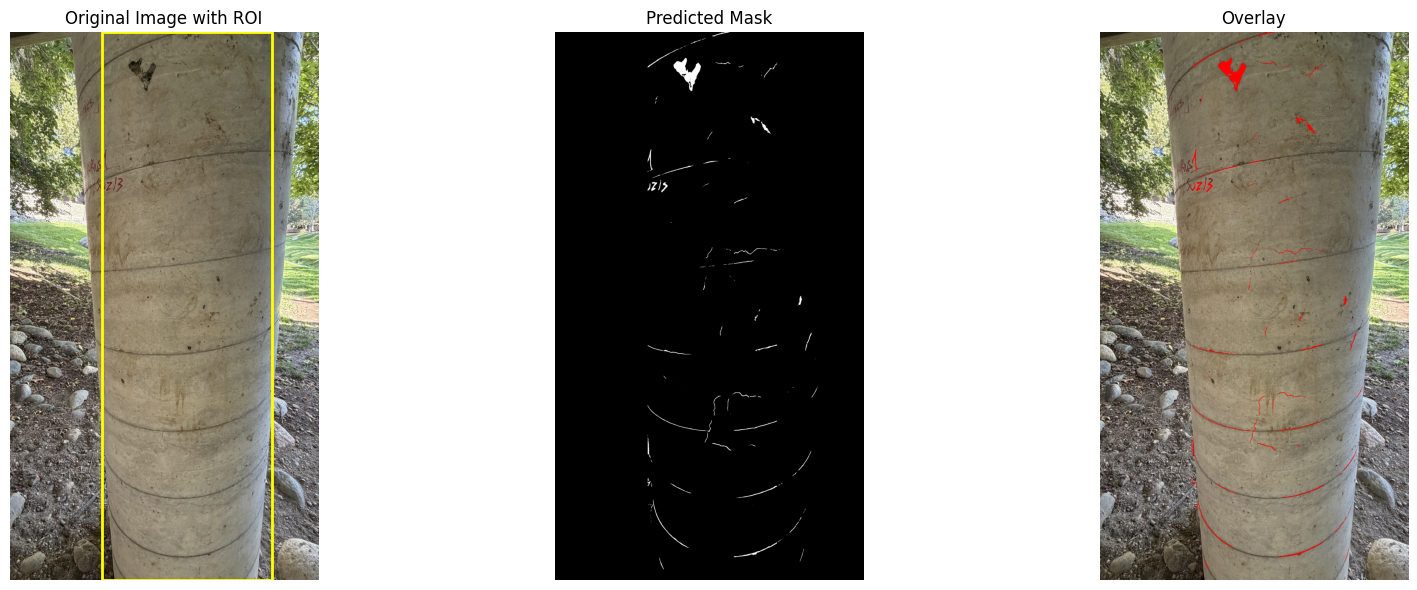

In [14]:
roi_image = config.DATA_ROOT / "reno_bridge_sample" / "IMG_0739.jpeg"
roi_coordinates = (0.3, 0.0, 0.85, 1.0)

if not roi_image.exists():
    raise FileNotFoundError(f"Bridge image not found: {roi_image}")

full_prediction, roi_figure = predict_and_plot_roi(
    model=roi_model,
    image=roi_image,
    roi_relative=roi_coordinates,
    device=config.DEVICE,
)
